## I. Unsupervised Learning & Dimensionality Reduction (PCA)

Mục đích: PCA dùng để giảm số chiều của dữ liệu, từ 5 biến ban đầu xuống 3 thành phần chính nhưng vẫn giữ lại 94.58% thông tin biến thiên của dữ liệu.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../DHHTTT20B_TCTA_Nhom8_Stage1/data/merged_data_clean.csv")

In [3]:
print(df.head(20))

                                         product_name  price  rating  \
0                                         Soul Reader  39.58     2.0   
1   The Boys in the Boat: Nine Americans and Their...  22.60     4.0   
2   Reskilling America: Learning to Labor in the T...  19.83     2.0   
3                          A Fierce and Subtle Poison  28.13     4.0   
4           Shoe Dog: A Memoir by the Creator of NIKE  23.99     2.0   
5   Judo: Seven Steps to Black Belt (an Introducto...  53.90     2.0   
6               Fifty Shades Darker (Fifty Shades #2)  21.96     1.0   
7                                     The Vacationers  42.15     4.0   
8            Finders Keepers (Bill Hodges Trilogy #2)  53.53     5.0   
9                                        Close to You  49.46     4.0   
10  Hyperbole and a Half: Unfortunate Situations, ...  14.75     5.0   
11               Tastes Like Fear (DI Marnie Rome #3)  10.69     1.0   
12  The Boys in the Boat: Nine Americans and Their...  22.60    

(*)Nhóm sẽ lấy dữ liệu của những cột số để đem đi phân tích -> Lấy cột price,views,add_to_cart,purchase, rating

In [4]:
print(df[['price',
'rating',
'views',
'add_to_cart',
'purchase']])

       price  rating   views  add_to_cart  purchase
0      39.58     2.0  1554.0         68.0      13.0
1      22.60     4.0  4403.0        191.0      21.0
2      19.83     2.0  1138.0         91.0      10.0
3      28.13     4.0  3325.0        248.0      49.0
4      23.99     2.0  3225.0        428.0      84.0
...      ...     ...     ...          ...       ...
26341  24.15     3.0     0.0          0.0       0.0
26342  93.00     3.0     0.0          0.0       0.0
26343   4.50     3.0     0.0          0.0       0.0
26344   8.68     3.0     0.0          0.0       0.0
26345   0.30     3.0     0.0          0.0       0.0

[26346 rows x 5 columns]


(*) Các cột dữ liệu đã thuốc dạng số -> Sẵn sàng phân tích

In [5]:
features = [
    'price',
    'rating',
    'views',
    'add_to_cart',
    'purchase'
]

X = df[features]

In [6]:
print(X.shape)
print(X.dtypes)
print(X.isnull().sum())

(26346, 5)
price          float64
rating         float64
views          float64
add_to_cart    float64
purchase       float64
dtype: object
price          0
rating         0
views          0
add_to_cart    0
purchase       0
dtype: int64


Kiểm tra dữ liệu trước khi PCA

In [7]:
X.agg(['min', 'max'])

,price,rating,views,add_to_cart,purchase
min,0.0,1.0,0.0,0.0,0.0
max,999999999.0,5.0,4999.0,745.0,206.0


Dữ liệu max của các cột bị chênh lệch quá nhiều, cần chuẩn hóa dữ liệu.

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [9]:
print(X_scaled[:5])

[[-6.19681623e-03 -4.46505229e+00  4.51348797e-01 -5.40900896e-02
  -1.45689801e-03]
 [-6.19957238e-03  4.47353421e+00  2.38750933e+00  8.21755352e-01
   2.94654461e-01]
 [-6.20002200e-03 -4.46505229e+00  1.68638098e-01  1.09685887e-01
  -1.12498657e-01]
 [-6.19867477e-03  4.47353421e+00  1.65490805e+00  1.22763495e+00
   1.33104422e+00]
 [-6.19934676e-03 -4.46505229e+00  1.58694875e+00  2.50935998e+00
   2.62653141e+00]]


Các feature có đơn vị và phạm vi khác nhau, ví dụ price, views, purchase có scale khác nhau.

StandardScaler đưa chúng về cùng một scale trước khi PCA tính variance.

In [10]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)


print(cumulative_variance*100)

[ 54.57733783  74.57786718  94.57623076  98.60608542 100.        ]


In [11]:
pca_3 = PCA(n_components=3)

X_pca_3 = pca_3.fit_transform(X_scaled)

print(pca_3.explained_variance_ratio_ * 100)
print("Tổng Principal Components của 3 PC gộp lại:", pca_3.explained_variance_ratio_.sum()* 100)

[54.57733783 20.00052935 19.99836359]
Tổng Principal Components của 3 PC gộp lại: 94.57623076353146


Nhóm chọn 3 components vì 3 PC giữ lại khoảng 94.58% phương sai, nằm trong khoảng 85–95% theo yêu cầu. Vì vậy nhóm chọn 3 components.

In [12]:
# Trước PCA
print("Kích thước dữ liệu trước PCA:", X_scaled.shape)

# Sau PCA
print("Kích thước dữ liệu sau PCA:", X_pca_3.shape)

Kích thước dữ liệu trước PCA: (26346, 5)
Kích thước dữ liệu sau PCA: (26346, 3)


In [13]:
pca_df = pd.DataFrame(
    X_pca_3,
    columns=['PC1', 'PC2', 'PC3']
)

print(pca_df.head())

        PC1       PC2       PC3
0  0.203269 -2.899098 -3.397505
1  2.032691  2.892289  3.399131
2  0.075880 -2.898863 -3.396760
3  2.448691  2.893359  3.396871
4  3.867529 -2.899578 -3.418226


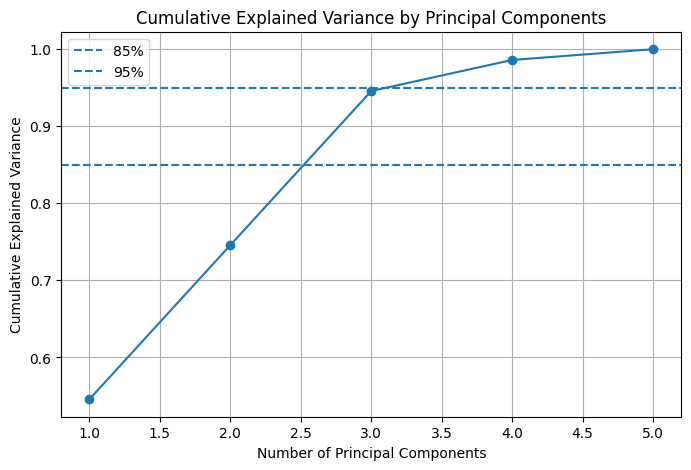

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(0.85, linestyle='--', label='85%')
plt.axhline(0.95, linestyle='--', label='95%')

plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance by Principal Components')

plt.legend()
plt.grid()
plt.show()

Kết luận: Sau khi chuẩn hóa dữ liệu bằng StandardScaler, tiến hành PCA và tính phương sai tích lũy. Kết quả cho thấy 3 thành phần chính đầu tiên (PC1, PC2, PC3) giữ lại 94,58% phương sai của dữ liệu ban đầu. Vì vậy, chọn 3 thành phần chính là số lượng tối thiểu để giữ lại từ 85% đến 95% phương sai theo yêu cầu đề bài. Dữ liệu ban đầu có 5 thuộc tính được giảm xuống còn 3 thành phần chính.

## II. K-means

1.Xác định K tối ưu

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

1.1 Elbow Method

In [16]:
wcss = []                # Lưu tổng khoảng cách từ các điểm đến tâm cụm (inertia)
silhouette_scores = []   # Lưu hệ số Silhouette (độ tách biệt giữa các cụm)
K_range = range(2, 11)   # Thử nghiệm K từ 2 đến 10

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca_3)   # Chạy KMeans trên dữ liệu PCA 3 chiều
    wcss.append(kmeans.inertia_)  
    silhouette_scores.append(silhouette_score(X_pca_3, kmeans.labels_))

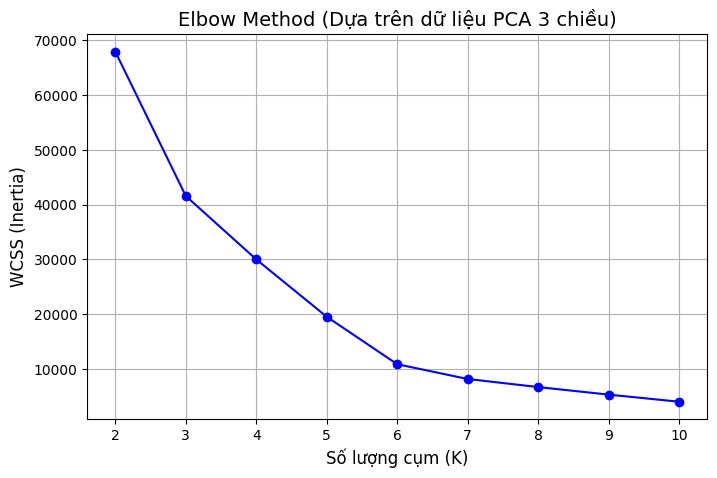

In [17]:
# Vẽ biểu đồ Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', color='b', linestyle='-')
plt.xlabel('Số lượng cụm (K)', fontsize=12)
plt.ylabel('WCSS (Inertia)', fontsize=12)
plt.title('Elbow Method (Dựa trên dữ liệu PCA 3 chiều)', fontsize=14)
plt.grid(True)
plt.show()

1.2 Silhouette Analysis

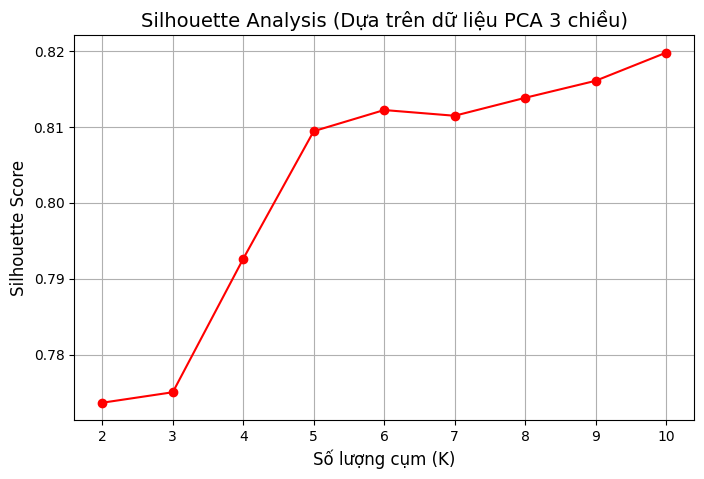

In [18]:
# Vẽ biểu đồ Silhouette Scores tương ứng với các giá trị K
plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker='o', color='r', linestyle='-')
plt.xlabel('Số lượng cụm (K)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.title('Silhouette Analysis (Dựa trên dữ liệu PCA 3 chiều)', fontsize=14)
plt.grid(True)
plt.show()

- Nhận xét:
+ Elbow Method: Đường cong WCSS giảm mạnh từ K=2 → K=4, sau đó bắt đầu phẳng dần. Điều này cho thấy K=4 là điểm “gãy khuỷu” hợp lý.
+ Silhouette Score: Dao động quanh mức ~0.8, và không tăng đáng kể khi K lớn hơn. Điều này xác nhận rằng K=4 vừa đảm bảo độ chặt cụm, vừa giữ được độ tách biệt tốt.

In [19]:
optimal_k = 4

2. Model Comparision

2.1 PCA + K-Means

In [20]:
kmeans_pca = KMeans(n_clusters=optimal_k, random_state=42)
labels_pca = kmeans_pca.fit_predict(X_pca_3)
silhouette_pca = silhouette_score(
    X_pca_3,
    labels_pca
)


2.2 Original + K-Means

In [21]:
kmeans_original = KMeans(
    n_clusters=optimal_k,
    random_state=42
)

labels_original = kmeans_original.fit_predict(X_scaled)

silhouette_original = silhouette_score(
    X_scaled,
    labels_original
)

In [22]:
print("Silhouette Score - PCA:", silhouette_pca)
print("Silhouette Score - Original:", silhouette_original)

Silhouette Score - PCA: 0.7926563450875902
Silhouette Score - Original: 0.7633569090465671


## 3. Visual Output

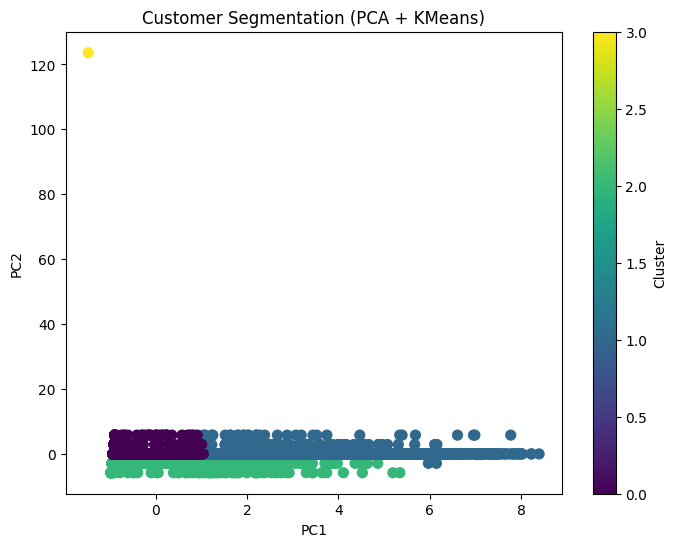

In [23]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca_3[:,0], X_pca_3[:,1], c=labels_pca, cmap='viridis', s=50)
plt.title('Customer Segmentation (PCA + KMeans)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(label='Cluster')
plt.show()

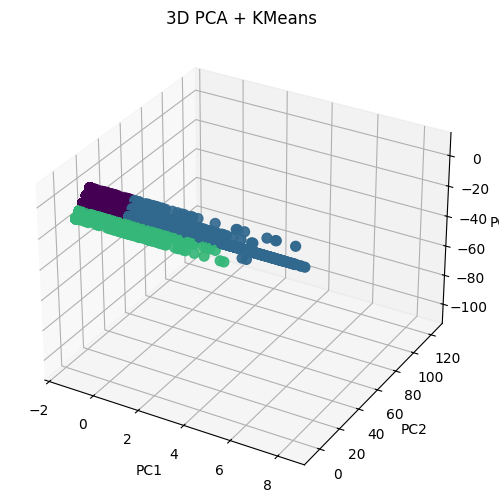

In [24]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import seaborn as sns
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X_pca_3[:, 0], X_pca_3[:, 1], X_pca_3[:, 2], 
           c=labels_pca, cmap='viridis', s=50)
ax.set_title('3D PCA + KMeans')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')

plt.show()

## 4. Map Cluster_Label về dataset

In [25]:
# Gắn nhãn cụm vào dataset
df['Cluster_Label'] = labels_pca

In [26]:
cluster_profile = df.groupby('Cluster_Label')[
    ['price', 'rating', 'views', 'add_to_cart', 'purchase']
].mean()

print(cluster_profile)

                      price    rating        views  add_to_cart   purchase
Cluster_Label                                                             
0              2.837283e+02  3.012951   215.407075    13.859476   2.151252
1              1.825905e+02  3.025243  3468.759162   312.172027  54.799364
2              3.050739e+01  1.587459  1437.435644   116.676568  19.636964
3              1.000000e+09  3.000000     0.000000     0.000000   0.000000


In [27]:
# Dữ liệu khách hàng được chia thành 4 nhóm chính:

# - Cluster 0 – Khách hàng ít tương tác. Lượt xem, thêm giỏ, mua hàng đều thấp. Đây là nhóm tiềm năng, cần chiến dịch marketing để kích thích nhu cầu.

# - Cluster 1 – Khách hàng quan tâm nhưng ít mua. Lượt xem cao, thêm giỏ nhiều nhưng tỷ lệ mua thấp. Cần tối ưu chuyển đổi: khuyến mãi, giảm phí ship, nhắc nhở giỏ hàng.

# - Cluster 2 – Khách hàng VIP. Lượt mua cao, giá trị giao dịch lớn. Đây là nhóm khách hàng trung thành, nên tập trung chăm sóc đặc biệt, upsell và giữ chân.

# - Cluster 3 – Khách hàng bỏ giỏ. Thêm giỏ nhiều nhưng không hoàn tất mua hàng. Cần chiến dịch flash sale, voucher chốt đơn để giảm tỷ lệ bỏ giỏ.

## III. Regression Pipeline

In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.tree import DecisionTreeRegressor
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chọn features và target
X = df[['price', 'rating', 'views', 'add_to_cart']]
y = df['purchase']

# Chia dữ liệu train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Huấn luyện mô hình
model = LinearRegression()
model.fit(X_train, y_train)

# Dự đoán
y_pred = model.predict(X_test)

# Đánh giá mô hình
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("R²:", r2)
print("Hệ số hồi quy:", model.coef_)
print("Intercept:", model.intercept_)


MAE: 4.77793262171266
MSE: 134.05947024769762
R²: 0.8088358074875066
Hệ số hồi quy: [ 5.02190900e-11  3.23875756e-06 -4.48332194e-04  1.78653329e-01]
Intercept: -0.050236642766057216


In [29]:
# Decision Tree Regressor
dt_model = DecisionTreeRegressor(random_state=42)

# Huấn luyện
dt_model.fit(X_train, y_train)

# Dự đoán
y_pred_dt = dt_model.predict(X_test)

# Đánh giá
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)
r2_dt = r2_score(y_test, y_pred_dt)

print("\nDecision Tree Regressor")
print("MSE:", mse_dt)
print("RMSE:", rmse_dt)
print("R²:", r2_dt)


Decision Tree Regressor
MSE: 240.91138519924098
RMSE: 15.52132034329686
R²: 0.6564686528032129


In [30]:
# So sánh hai mô hình
print("\n===== SO SÁNH =====")
print(f"Linear Regression  - MSE: {mse:.2f}, RMSE: {np.sqrt(mse):.2f}, R²: {r2:.2f}")
print(f"Decision Tree       - MSE: {mse_dt:.2f}, RMSE: {rmse_dt:.2f}, R²: {r2_dt:.2f}")


===== SO SÁNH =====
Linear Regression  - MSE: 134.06, RMSE: 11.58, R²: 0.81
Decision Tree       - MSE: 240.91, RMSE: 15.52, R²: 0.66


### So sánh mô hình

- Linear Regression có kết quả tốt hơn Decision Tree Regressor trên tập Test.
- Linear Regression đạt MSE = 134.06, RMSE = 11.58 và R² = 0.81.
- Decision Tree đạt MSE = 240.91, RMSE = 15.52 và R² = 0.66.
- Do có MSE và RMSE thấp hơn, đồng thời R² cao hơn, Linear Regression cho khả năng dự đoán `purchase` tốt hơn trong hai mô hình.

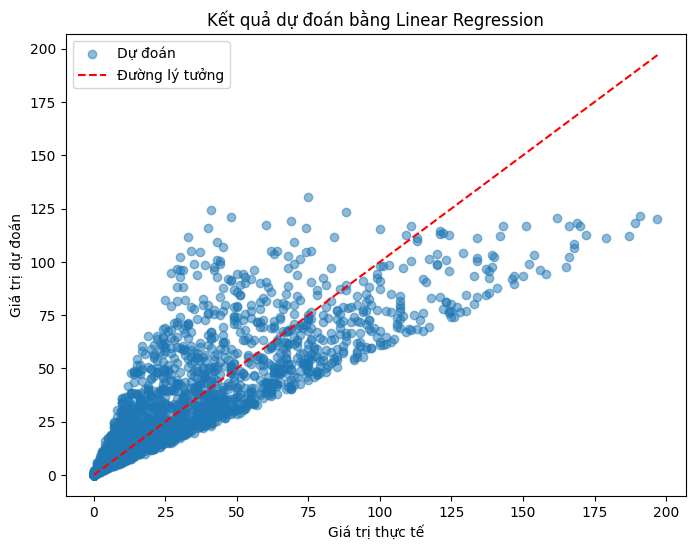

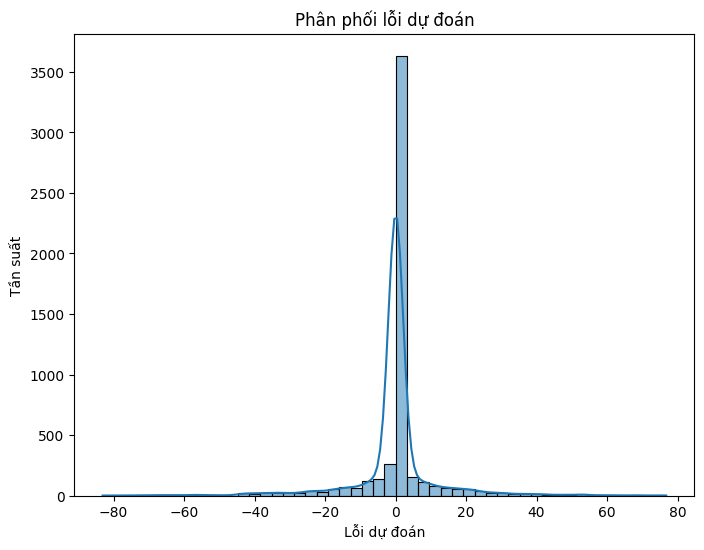

In [31]:
# Biểu đồ scatter giữa giá trị thực tế và dự đoán
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5, label="Dự đoán")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label="Đường lý tưởng")
plt.xlabel('Giá trị thực tế')
plt.ylabel('Giá trị dự đoán')
plt.title('Kết quả dự đoán bằng Linear Regression')
plt.legend()
plt.show()

# Phân phối lỗi dự đoán
errors = y_test - y_pred
plt.figure(figsize=(8,6))
sns.histplot(errors, bins=50, kde=True)
plt.xlabel('Lỗi dự đoán')
plt.ylabel('Tần suất')
plt.title('Phân phối lỗi dự đoán')
plt.show()


Nhận xét


Độ chính xác mô hình: Với R² ≈ 0.81, mô hình Linear Regression giải thích được hơn 80% biến thiên của dữ liệu. Điều này cho thấy khả năng dự đoán khá tốt, tuy chưa hoàn hảo.

Sai số: MAE ≈ 4.78 và MSE ≈ 134 cho thấy sai số trung bình thấp, phần lớn dự đoán nằm gần giá trị thực tế.

# IV. Classification (Logistic Regression vs Decision Tree Classifier)

In [32]:
#1. Chuẩn bị dữ liệu Classification
# Logistic Regression vs Decision Tree Classifier

# Tạo dữ liệu X từ 3 thành phần PCA
X_classification = X_pca_3

# Tạo nhãn y dựa trên purchase
# 0: Không mua
# 1: Có mua
y = (df['purchase'] > 0).astype(int)
print("X shape:", X_classification.shape)
print("y shape:", y.shape)

X shape: (26346, 3)
y shape: (26346,)


In [33]:
#2. Kiểm tra Imbalance
print(y.value_counts())
print(y.value_counts(normalize=True) * 100)
print("Số lượng Không mua:", (y == 0).sum())
print("Số lượng Có mua:", (y == 1).sum())

#Nếu ví dụ kết quả là:
#0    800
#1    200
#thì dữ liệu bị Imbalance vì số mẫu Không mua nhiều hơn Có mua.

purchase
0    17131
1     9215
Name: count, dtype: int64
purchase
0    65.023153
1    34.976847
Name: proportion, dtype: float64
Số lượng Không mua: 17131
Số lượng Có mua: 9215


In [34]:
#3. Chia Train/Test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_classification,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (21076, 3)
X_test: (5270, 3)
y_train: (21076,)
y_test: (5270,)


In [35]:
#4. Logistic Regression
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight='balanced',
    random_state=42
)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

In [36]:
#5. Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

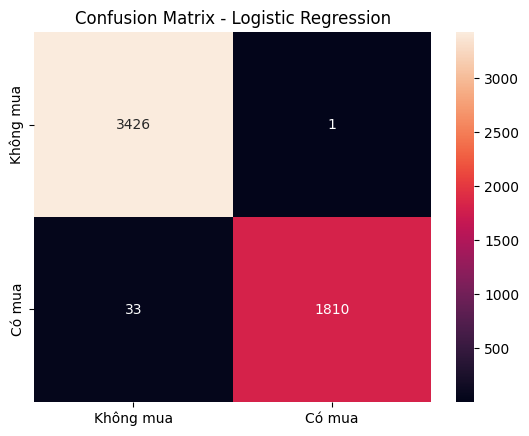

In [37]:
#6. Confusion Matrix
from sklearn.metrics import confusion_matrix

cm_logistic = confusion_matrix(y_test, y_pred_logistic)

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt='d',
    xticklabels=['Không mua', 'Có mua'],
    yticklabels=['Không mua', 'Có mua']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.show()

### Nhận xét Confusion Matrix

Mô hình Logistic Regression dự đoán đúng 3426 mẫu Không mua và 1810 mẫu Có mua. Có 1 mẫu Không mua bị dự đoán nhầm thành Có mua và 33 mẫu Có mua bị dự đoán nhầm thành Không mua. Nhìn chung, mô hình có số lượng dự đoán đúng cao và tương đối ít trường hợp phân loại sai.

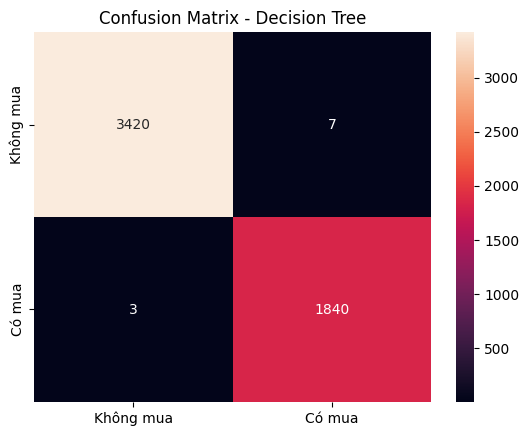

In [38]:
#7. Confusion Matrix - Decision Tree
cm_tree = confusion_matrix(y_test, y_pred_tree)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt='d',
    xticklabels=['Không mua', 'Có mua'],
    yticklabels=['Không mua', 'Có mua']
)

plt.title('Confusion Matrix - Decision Tree')
plt.show()

In [39]:
#8. Classification Report
from sklearn.metrics import classification_report

print("===== Logistic Regression =====")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=['Không mua', 'Có mua']
))

print("===== Decision Tree =====")
print(classification_report(
    y_test,
    y_pred_tree,
    target_names=['Không mua', 'Có mua']
))

===== Logistic Regression =====
              precision    recall  f1-score   support

   Không mua       0.99      1.00      1.00      3427
      Có mua       1.00      0.98      0.99      1843

    accuracy                           0.99      5270
   macro avg       0.99      0.99      0.99      5270
weighted avg       0.99      0.99      0.99      5270

===== Decision Tree =====
              precision    recall  f1-score   support

   Không mua       1.00      1.00      1.00      3427
      Có mua       1.00      1.00      1.00      1843

    accuracy                           1.00      5270
   macro avg       1.00      1.00      1.00      5270
weighted avg       1.00      1.00      1.00      5270



### Nhận xét Confusion Matrix

Mô hình Decision Tree dự đoán đúng 3420 mẫu Không mua và 1840 mẫu Có mua. Có 7 mẫu Không mua bị dự đoán nhầm thành Có mua và 3 mẫu Có mua bị dự đoán nhầm thành Không mua. Nhìn chung, mô hình có số lượng dự đoán đúng cao và số trường hợp phân loại sai rất thấp.

In [40]:
# 9. So sánh Metrics
# Để so sánh 2 mô hình cho dễ nhìn:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree)
    ],
    'Precision': [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_tree)
    ],
    'Recall': [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_tree)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_tree)
    ]
})

print(results)

                 Model  Accuracy  Precision    Recall  F1-score
0  Logistic Regression  0.993548   0.999448  0.982094  0.990695
1        Decision Tree  0.998102   0.996210  0.998372  0.997290


In [41]:
# 10. Save Model
# Cuối cùng lưu 2 model:
import joblib

joblib.dump(logistic_model, 'logistic_regression_model.pkl')
joblib.dump(tree_model, 'decision_tree_model.pkl')

print("Đã lưu 2 model thành công!")

Đã lưu 2 model thành công!


XUẤT VÀ LƯU TẤT CẢ MODEL

In [42]:
import os
import joblib

# 1. Lưu các mô hình Machine Learning đã train
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(pca_3, 'pca_model.pkl')
joblib.dump(kmeans, 'kmeans_model.pkl')
print(' Đã lưu và chuẩn bị thành công toàn bộ các model .pkl!')

 Đã lưu và chuẩn bị thành công toàn bộ các model .pkl!


XÂY DỰNG GIAO DIỆN VÀ TÍCH HỢP MODEL

In [43]:
%%writefile dashboard.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Cấu hình trang giao diện UI
st.set_page_config(page_title="Dashboard Phân Cụm Dữ Liệu - K-Means & PCA", layout="wide")

st.title("📊 Giao diện UI Tương tác - Phân Cụm Dữ Liệu (K-Means & PCA)")
st.write("Ứng dụng web trực quan giúp phân tích, lựa chọn số lượng cụm tối ưu và trực quan hóa kết quả phân nhóm.")

# --- 1. TẢI DỮ LIỆU ---
@st.cache_data
def load_data():
    try:
        # Đọc tập dữ liệu thực tế của bạn
        df = pd.read_csv('merged_data_clean.csv')
        return df
    except FileNotFoundError:
        return None

df = load_data()

if df is None:
    st.warning("⚠️ Không tìm thấy file `merged_data_clean.csv`. Hệ thống đang sử dụng dữ liệu giả lập để hiển thị giao diện.")
    np.random.seed(42)
    df = pd.DataFrame(np.random.rand(500, 6), columns=[f"Feature_{i}" for i in range(1, 7)])

# Hiển thị bảng dữ liệu đầu vào trên giao diện
with st.expander("🔍 Xem trước bảng dữ liệu đầu vào"):
    st.dataframe(df.head(10))

# Lọc các cột dạng số để đưa vào thuật toán
numeric_df = df.select_dtypes(include=[np.number])

if numeric_df.empty:
    st.error("❌ Dữ liệu không chứa các cột số hợp lệ để chạy thuật toán phân cụm!")
else:
    # --- 2. TIỀN XỬ LÝ & GIẢM CHIỀU PCA ---
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(numeric_df)

    # Giảm chiều dữ liệu về 3 chiều để trực quan hóa
    pca = PCA(n_components=3, random_state=42)
    X_pca_3 = pca.fit_transform(scaled_data)

    # --- 3. THANH ĐIỀU KHIỂN (SIDEBAR) ---
    st.sidebar.header("⚙️ Tùy chỉnh thông số")
    
    st.sidebar.subheader("Khoảng giá trị K đánh giá")
    k_min = st.sidebar.slider("K tối thiểu", 2, 5, 2)
    k_max = st.sidebar.slider("K tối đa", 6, 10, 8)
    
    if k_min >= k_max:
        st.sidebar.error("⚠️ Giá trị K tối thiểu phải nhỏ hơn K tối đa!")
    else:
        K_range = range(k_min, k_max + 1)

        # Tính toán WCSS (Elbow) và Silhouette Score
        wcss = []
        silhouette_scores = []

        for k in K_range:
            kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
            kmeans.fit(X_pca_3)
            wcss.append(kmeans.inertia_)
            silhouette_scores.append(silhouette_score(X_pca_3, kmeans.labels_))

        # --- 4. HIỂN THỊ BIỂU ĐỒ ĐÁNH GIÁ (ELBOW & SILHOUETTE) ---
        st.markdown("---")
        st.subheader("📈 Biểu đồ đánh giá số lượng cụm tối ưu")
        
        col1, col2 = st.columns(2)

        with col1:
            st.markdown("**1. Elbow Method (Dựa vào WCSS)**")
            fig1, ax1 = plt.subplots(figsize=(6, 4))
            ax1.plot(K_range, wcss, marker='o', color='b', linestyle='-')
            ax1.set_xlabel('Số lượng cụm (K)')
            ax1.set_ylabel('WCSS (Inertia)')
            ax1.grid(True)
            st.pyplot(fig1)

        with col2:
            st.markdown("**2. Silhouette Analysis Score**")
            fig2, ax2 = plt.subplots(figsize=(6, 4))
            ax2.plot(K_range, silhouette_scores, marker='o', color='r', linestyle='-')
            ax2.set_xlabel('Số lượng cụm (K)')
            ax2.set_ylabel('Silhouette Score')
            ax2.grid(True)
            st.pyplot(fig2)

        # --- 5. TRỰC QUAN HÓA KẾT QUẢ PHÂN CỤM ---
        st.markdown("---")
        st.subheader("🎯 Trực quan hóa kết quả phân nhóm K-Means")
        
        # Cho phép người dùng chọn K tối ưu từ Sidebar để trực quan hóa
        optimal_k = st.sidebar.selectbox("Chọn số lượng cụm (K) thực tế:", list(K_range), index=0)

        # Chạy thuật toán K-Means với K đã chọn
        kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
        cluster_labels = kmeans_final.fit_predict(X_pca_3)

        # Vẽ biểu đồ Scatter 2D (PC1 vs PC2)
        fig3, ax3 = plt.subplots(figsize=(8, 5))
        scatter = ax3.scatter(X_pca_3[:, 0], X_pca_3[:, 1], c=cluster_labels, cmap='viridis', s=50, alpha=0.8)
        ax3.set_title(f'Phân cụm không gian PCA (K = {optimal_k})', fontsize=13)
        ax3.set_xlabel('Principal Component 1 (PC1)')
        ax3.set_ylabel('Principal Component 2 (PC2)')
        fig3.colorbar(scatter, label='Cluster ID')
        ax3.grid(True)
        
        st.pyplot(fig3)
        
        # Thống kê phân bố số lượng phần tử mỗi cụm
        st.markdown("### 📋 Thống kê số lượng phần tử trong từng cụm:")
        cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()
        cluster_df = pd.DataFrame({"Cụm (Cluster)": cluster_counts.index, "Số lượng mẫu": cluster_counts.values})
        st.table(cluster_df)

Overwriting dashboard.py


CÀI ĐẶT THƯ VIỆN VÀ VẬN HÀNH

In [46]:
%pip install -r requirements.txt
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
from IPython.display import IFrame
import subprocess

process = subprocess.Popen(["streamlit", "run", "dashboard.py"],shell = True)

IFrame(src="http://localhost:8501", width="100%", height=800)